<a href="https://colab.research.google.com/github/VasilisPapageorgiou/Reliability---Partially-Observed/blob/main/Sim2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter 1 to START NEW or 2 to RESUME  1
Checkpoint saved 0 completed tasks
Computing observation laws for 1182 models.
Precomputed 100 models
Precomputed 200 models
Precomputed 300 models
Precomputed 400 models
Precomputed 500 models
Precomputed 600 models
Precomputed 700 models
Precomputed 800 models
Precomputed 900 models
Precomputed 1000 models
Precomputed 1100 models
Checkpoint saved 1 completed tasks
Validation checks passed.
Completed sample|endpoint_equivalent_exponential|0
Completed sample|erlang_fast_repair|0
Completed sample|hyperexponential_slower_repair|0
Completed sample|off_grid_erlang|0
Checkpoint saved 5 completed tasks
Completed sample|endpoint_equivalent_exponential|1
Completed sample|erlang_fast_repair|1
Completed sample|hyperexponential_slower_repair|1
Completed sample|off_grid_erlang|1
Checkpoint saved 9 completed tasks
Completed sample|endpoint_equivalent_exponential|2
Completed sample|erlang_fast_repair|2
Completed sample|hyperexponential_slower_repair|2
Completed

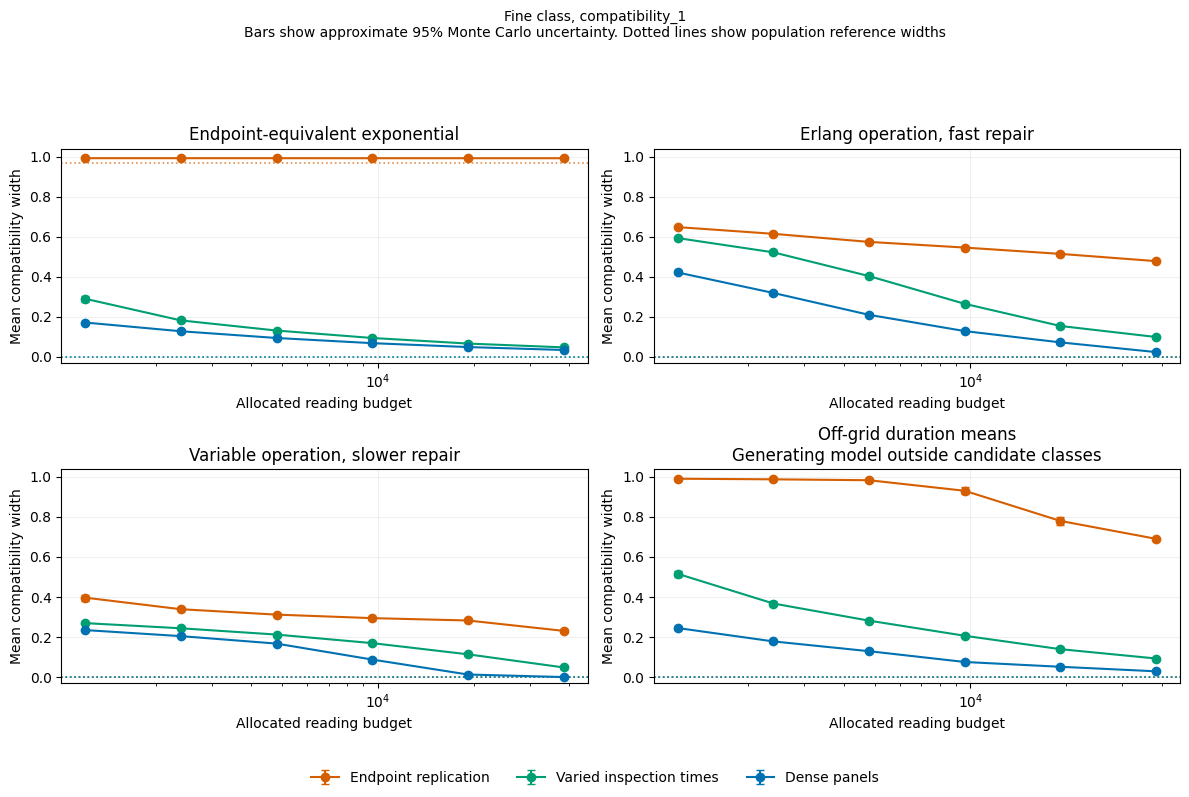

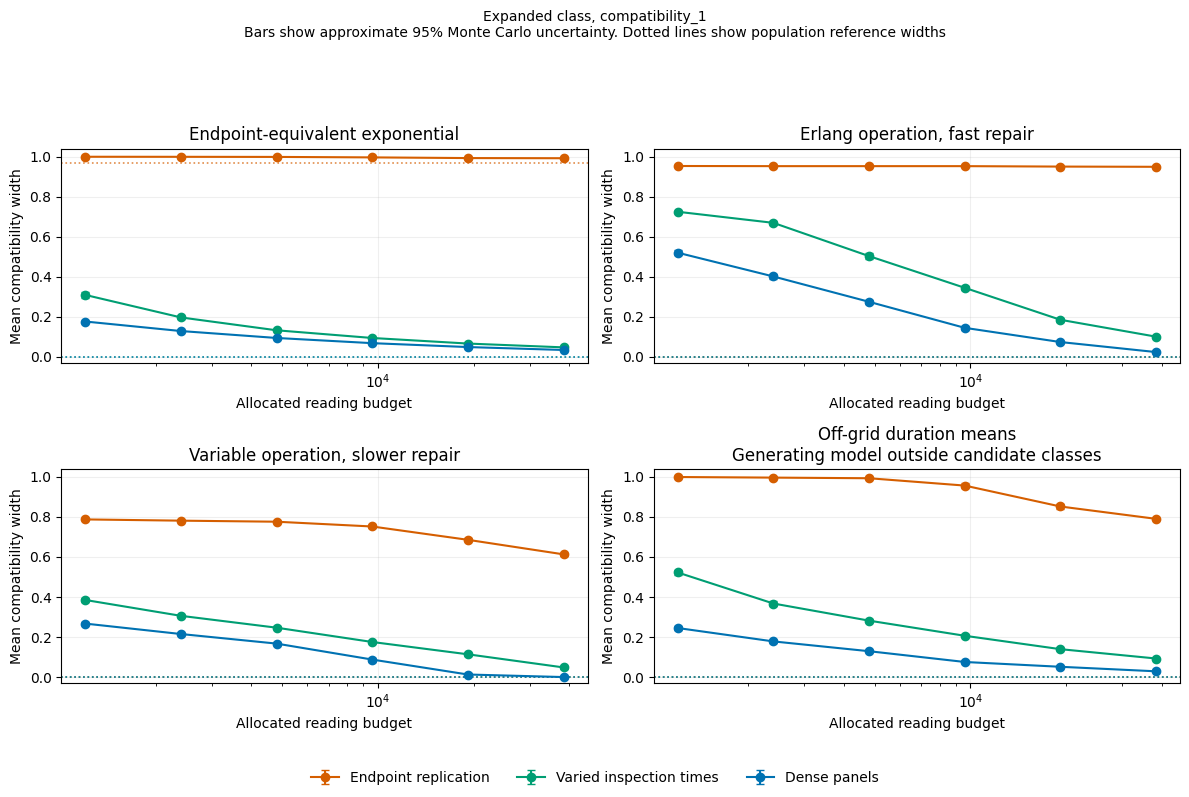

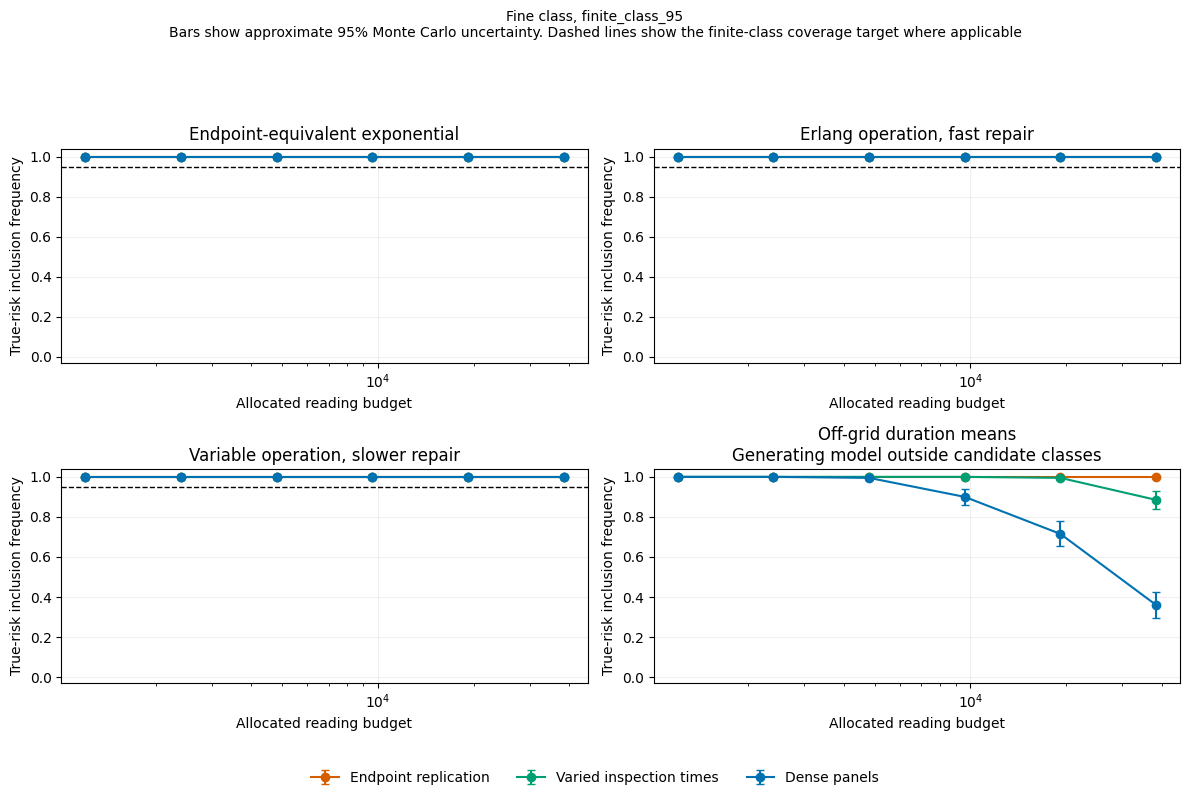

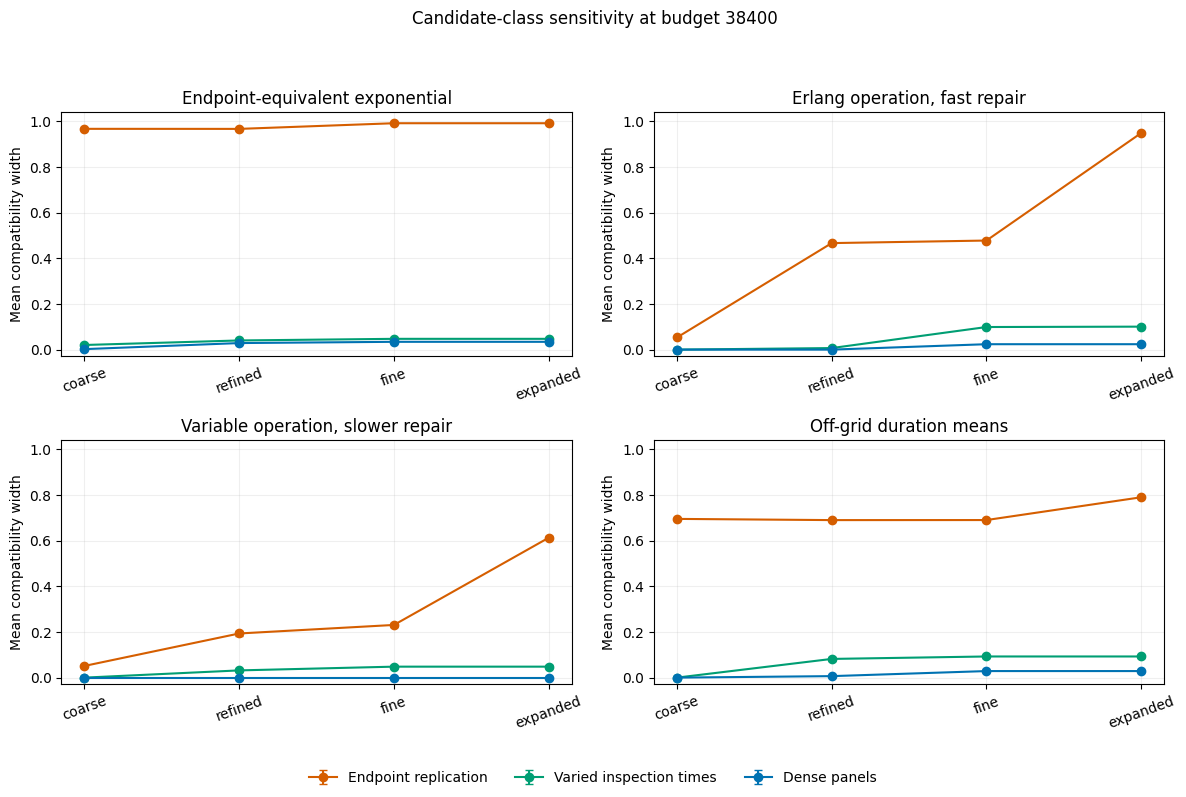

Checkpoint saved 801 completed tasks
Completed. Results are in /content/SemiMarkov_Experiments/experiment_2_strengthened
Inspect population_references.csv and paired_design_comparisons.csv.
Interpret interval widths together with risk inclusion.
Download the checkpoint or ZIP before the Colab runtime is deleted.
Checkpoint saved 801 completed tasks


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ================================================================
# STRENGTHENED SIMULATION 2
# Inspection design, information, and missed-failure risk
#
# Main question
# How should a fixed reading budget be allocated between
# additional systems and additional observations per system?
#
# Features
#   Four nested finite candidate classes
#   Six reading budgets
#   Population reference sets
#   Paired design comparisons using common physical trajectories
#   Compatibility-threshold sensitivity
#   Conservative finite-class confidence sets
#   A deliberately off-grid generating model
#   Monte Carlo standard errors
#   Local checkpoints and resume
#
# No Google Drive connection.
# ================================================================

import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import json
import gzip
import time
import hashlib
import shutil
import itertools
import platform
import uuid
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy.linalg import expm, block_diag


# ================================================================
# Configuration
# ================================================================

PROFILE = "publication"       # "diagnostic" or "publication"
SEED = 20261117

CHECKPOINT_SECONDS = 20 * 60
DOWNLOAD_ON_FINISH = True
RUN_VALIDATION = True

CODE_VERSION = "simulation2_nested_designs_v1"

PROFILES = {
    "diagnostic": {
        "repetitions": 5,
        "budgets": [1200, 4800, 19200],
        "validation_systems": 10000,
    },
    "publication": {
        "repetitions": 200,
        "budgets": [1200, 2400, 4800, 9600, 19200, 38400],
        "validation_systems": 30000,
    },
}

if PROFILE not in PROFILES:
    raise ValueError("PROFILE must be diagnostic or publication.")

CFG = PROFILES[PROFILE].copy()

H = 6.0
TARGET = (0.0, H)
SHAPES = (0, 1, 3)

# Shape 0 is a fixed two-component hyperexponential family.
# Shape 1 is exponential.
# Shape 3 is Erlang with three phases.
#
# All systems begin newly in operation.
# Operating and repair durations are independently renewed at transitions.
# Inspections do not change the physical path.

DESIGNS = {
    "replication": [(0.0, H)],
    "varied_pairs": [
        (0.0, v, H)
        for v in (0.5, 1.0, 2.0, 3.0, 4.0, 5.0)
    ],
    "dense_panels": [
        (0.0, 1.0, 2.0, 3.0, 4.0, 5.0, H)
    ],
}

DESIGN_ORDER = [
    "replication",
    "varied_pairs",
    "dense_panels",
]

DESIGN_LABELS = {
    "replication": "Endpoint replication",
    "varied_pairs": "Varied inspection times",
    "dense_panels": "Dense panels",
}

COLORS = {
    "replication": "#D55E00",
    "varied_pairs": "#009E73",
    "dense_panels": "#0072B2",
}

CLASS_ORDER = [
    "coarse",
    "refined",
    "fine",
    "expanded",
]

# Main compatibility threshold
# log L_hat - log L_theta <= multiplier * log(n + 1).
COMPATIBILITY_MULTIPLIERS = (0.5, 1.0, 2.0)

# Additional conservative finite-class confidence procedure.
ALPHA = 0.05

# Numerical tolerances for population calculations.
TV_EQUIVALENCE_TOLERANCE = 1e-10
KL_MINIMIZER_TOLERANCE = 1e-10
LIKELIHOOD_TOLERANCE = 1e-9

RISK_SEPARATIONS = (0.05, 0.10, 0.20)

BASE = (
    Path("/content") if Path("/content").exists() else Path.cwd()
) / "SemiMarkov_Experiments"

ROOT = BASE / "experiment_2_strengthened"

CP = None


# ================================================================
# Local checkpoints
# ================================================================

def json_default(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Cannot serialize {type(value)}")


def reproducible_rng(key):
    digest = hashlib.sha256(f"{SEED}|{key}".encode()).digest()
    return np.random.default_rng(
        int.from_bytes(digest[:8], "little")
    )


class LocalCheckpoint:
    def __init__(self, root, metadata):
        self.root = Path(root)
        self.metadata = metadata

        self.fingerprint = hashlib.sha256(
            json.dumps(metadata, sort_keys=True).encode()
        ).hexdigest()

        choice = input(
            "Enter 1 to START NEW or 2 to RESUME  "
        ).strip()

        while choice not in {"1", "2"}:
            choice = input("Please enter 1 or 2  ").strip()

        self.root.parent.mkdir(parents=True, exist_ok=True)

        if choice == "1" and self.root.exists():
            archive = self.root.with_name(
                self.root.name
                + "_archive_"
                + time.strftime("%Y%m%d_%H%M%S")
                + "_"
                + uuid.uuid4().hex[:6]
            )
            shutil.move(str(self.root), str(archive))
            print("Previous local run preserved in", archive)

        self.root.mkdir(parents=True, exist_ok=True)
        self.path = self.root / "checkpoint.json.gz"

        if choice == "2":
            if self.path.exists():
                raw = self.path.read_bytes()
            else:
                print(
                    "Upload checkpoint.json.gz produced by this code version."
                )
                try:
                    from google.colab import files
                except ImportError as exc:
                    raise FileNotFoundError(
                        f"Place checkpoint.json.gz in {self.root}"
                    ) from exc

                uploaded = files.upload()
                candidates = [
                    data
                    for name, data in uploaded.items()
                    if name.endswith(".json.gz")
                ]

                if len(candidates) != 1:
                    raise ValueError(
                        "Upload exactly one .json.gz checkpoint."
                    )
                raw = candidates[0]

            state = json.loads(
                gzip.decompress(raw).decode("utf-8")
            )

            if state.get("fingerprint") != self.fingerprint:
                raise ValueError(
                    "Checkpoint configuration does not match. "
                    "Restore the same settings or start a new run."
                )

            if not isinstance(state.get("tasks"), dict):
                raise ValueError("Invalid checkpoint task table.")

            self.state = state
            print(
                "Resuming",
                len(self.state["tasks"]),
                "completed tasks.",
            )
        else:
            self.state = {
                "fingerprint": self.fingerprint,
                "metadata": metadata,
                "tasks": {},
            }

        self.last_save = time.monotonic()
        self.save()

    def has(self, key):
        return key in self.state["tasks"]

    def commit(self, key, tables):
        # Only complete tasks are committed.
        self.state["tasks"][key] = tables
        self.tick()

    def save(self):
        self.state["saved_at_utc"] = time.strftime(
            "%Y-%m-%dT%H:%M:%SZ", time.gmtime()
        )

        raw = json.dumps(
            self.state,
            default=json_default,
            allow_nan=True,
        ).encode("utf-8")

        temporary = self.root / "checkpoint.tmp.gz"

        with gzip.open(temporary, "wb") as stream:
            stream.write(raw)

        os.replace(temporary, self.path)
        self.last_save = time.monotonic()

        print(
            "Checkpoint saved",
            len(self.state["tasks"]),
            "completed tasks",
            flush=True,
        )

    def tick(self):
        if time.monotonic() - self.last_save >= CHECKPOINT_SECONDS:
            self.save()

    def frame(self, table):
        rows = []
        for tables in self.state["tasks"].values():
            rows.extend(tables.get(table, []))
        return pd.DataFrame(rows)

    def export(self):
        names = {
            name
            for tables in self.state["tasks"].values()
            for name in tables
        }

        for name in sorted(names):
            self.frame(name).to_csv(
                self.root / f"{name}.csv", index=False
            )

        (self.root / "configuration.json").write_text(
            json.dumps(self.metadata, indent=2),
            encoding="utf-8",
        )


def heartbeat():
    if CP is not None:
        CP.tick()


def download_checkpoint():
    """Call after stopping execution to download completed progress."""
    if CP is None:
        raise RuntimeError("Checkpoint manager is not initialized.")

    CP.save()

    try:
        from google.colab import files
        files.download(str(CP.path))
    except ImportError:
        print("Checkpoint", CP.path)


def download_results():
    """Download results and checkpoint without the regenerable law cache."""
    if CP is not None:
        CP.save()
        CP.export()

    import zipfile

    archive = ROOT.parent / f"{ROOT.name}_results.zip"

    with zipfile.ZipFile(
        archive, "w", compression=zipfile.ZIP_DEFLATED
    ) as output:
        for path in sorted(ROOT.iterdir()):
            if path.is_file() and path.suffix != ".npz":
                output.write(path, arcname=path.name)

    try:
        from google.colab import files
        files.download(str(archive))
    except ImportError:
        print("Results archive", archive)


# ================================================================
# Nested candidate classes
# ================================================================

def parameter_key(parameters):
    # Used only to detect duplicate parameter entries.
    return (
        int(parameters[0]),
        int(parameters[1]),
        round(float(parameters[2]), 12),
        round(float(parameters[3]), 12),
    )


def geometric_refinement(values):
    values = sorted(float(value) for value in values)
    midpoints = [
        np.sqrt(left * right)
        for left, right in zip(values[:-1], values[1:])
    ]
    return sorted(values + midpoints)


def exponential_alias(total_rate, endpoint_failure=0.15):
    failure_rate = (
        endpoint_failure * total_rate
        / (-np.expm1(-total_rate * H))
    )
    repair_rate = total_rate - failure_rate

    if failure_rate <= 0 or repair_rate <= 0:
        raise ValueError("Invalid exponential alias.")

    return (
        1,
        1,
        float(1 / failure_rate),
        float(1 / repair_rate),
    )


def build_candidate_classes():
    models = []
    lookup = {}
    classes = {}

    def add(parameters):
        parameters = (
            int(parameters[0]),
            int(parameters[1]),
            float(parameters[2]),
            float(parameters[3]),
        )
        key = parameter_key(parameters)

        if key not in lookup:
            lookup[key] = len(models)
            models.append(parameters)

        return lookup[key]

    def add_phase_grid(means0, means1):
        for k0, k1, mean0, mean1 in itertools.product(
            SHAPES, SHAPES, means0, means1
        ):
            add((k0, k1, mean0, mean1))

    b = 0.15
    minimum_rate = -np.log1p(-b) / H

    alias_rates0 = list(
        np.geomspace(minimum_rate * 1.05, 4.0, 24)
    )
    aliases0 = [exponential_alias(rate) for rate in alias_rates0]

    for parameters in aliases0:
        add(parameters)

    means0_coarse = [2.0, 4.0, 8.0]
    means1_coarse = [0.3, 1.2]

    add_phase_grid(means0_coarse, means1_coarse)
    classes["coarse"] = np.arange(len(models), dtype=int)

    # Preserve all coarse models and insert additional mean values.
    means0_refined = geometric_refinement(means0_coarse)
    means1_refined = geometric_refinement(
        geometric_refinement(means1_coarse)
    )
    alias_rates1 = geometric_refinement(alias_rates0)

    for rate in alias_rates1:
        add(exponential_alias(rate))

    add_phase_grid(means0_refined, means1_refined)
    classes["refined"] = np.arange(len(models), dtype=int)

    means0_fine = geometric_refinement(means0_refined)
    means1_fine = geometric_refinement(means1_refined)
    alias_rates2 = geometric_refinement(alias_rates1)

    for rate in alias_rates2:
        add(exponential_alias(rate))

    add_phase_grid(means0_fine, means1_fine)
    classes["fine"] = np.arange(len(models), dtype=int)

    # A separate domain-expansion sensitivity analysis.
    means0_expanded = sorted(set([1.0, 16.0] + means0_fine))
    means1_expanded = sorted(set([0.15, 2.4] + means1_fine))

    add_phase_grid(means0_expanded, means1_expanded)
    classes["expanded"] = np.arange(len(models), dtype=int)

    return models, classes, lookup, aliases0


MODELS, CLASSES, MODEL_LOOKUP, BASE_ALIASES = build_candidate_classes()

SCENARIOS = [
    {
        "scenario": "endpoint_equivalent_exponential",
        "label": "Endpoint-equivalent exponential",
        "parameters": BASE_ALIASES[10],
        "purpose": "Structural ambiguity under endpoint replication",
    },
    {
        "scenario": "erlang_fast_repair",
        "label": "Erlang operation, fast repair",
        "parameters": (3, 3, 4.0, 0.3),
        "purpose": "Design comparison under increasing duration hazards",
    },
    {
        "scenario": "hyperexponential_slower_repair",
        "label": "Variable operation, slower repair",
        "parameters": (0, 3, 4.0, 1.2),
        "purpose": "Design comparison under heterogeneous operating durations",
    },
    {
        "scenario": "off_grid_erlang",
        "label": "Off-grid duration means",
        "parameters": (3, 3, 3.6, 0.55),
        "purpose": "Sensitivity to exclusion of the generating model",
    },
]

SCHEDULES = []
for schedules in DESIGNS.values():
    for schedule in schedules:
        schedule = tuple(schedule)
        if schedule not in SCHEDULES:
            SCHEDULES.append(schedule)

SCHEDULE_INDEX = {
    schedule: index for index, schedule in enumerate(SCHEDULES)
}

MASTER_TIMES = np.array(sorted({
    t
    for schedule in SCHEDULES
    for t in schedule
}), dtype=float)


# ================================================================
# Physical model and observation probabilities
# ================================================================

def duration_block(shape, mean):
    if mean <= 0:
        raise ValueError("Duration means must be positive.")

    if shape == 0:
        rates = (
            np.array([0.6, 3.0])
            * (0.5 / 0.6 + 0.5 / 3.0)
            / mean
        )
        return np.array([0.5, 0.5]), -np.diag(rates)

    alpha = np.zeros(shape)
    alpha[0] = 1.0

    matrix = -np.eye(shape) * shape / mean
    if shape > 1:
        matrix[np.arange(shape - 1), np.arange(1, shape)] = (
            shape / mean
        )

    return alpha, matrix


@lru_cache(maxsize=4096)
def physical_model(k0, k1, mean0, mean1):
    a, T = duration_block(k0, mean0)
    b, U = duration_block(k1, mean1)

    Q = block_diag(T, U)
    d = len(a)

    Q[:d, d:] = np.outer(-T.sum(axis=1), b)
    Q[d:, :d] = np.outer(-U.sum(axis=1), a)

    initial = np.r_[a, np.zeros(len(b))]
    states = np.r_[
        np.zeros(d, dtype=int),
        np.ones(len(b), dtype=int),
    ]

    return Q, initial, states, T, a


def observation_law(parameters, schedule):
    heartbeat()

    Q, initial, states, _, _ = physical_model(*tuple(parameters))
    rows = initial[None, :]
    schedule = np.asarray(schedule, dtype=float)

    if schedule[0] != 0 or not np.all(np.diff(schedule) > 0):
        raise ValueError("Invalid inspection schedule.")

    transitions = {}

    for dt in np.diff(schedule):
        dt = float(dt)

        if dt not in transitions:
            transitions[dt] = expm(Q * dt)

        prediction = rows @ transitions[dt]
        updated = np.empty((2 * len(rows), len(initial)))

        updated[0::2] = prediction * (states == 0)
        updated[1::2] = prediction * (states == 1)

        rows = updated

    probabilities = rows.sum(axis=1)

    if probabilities.min() < -1e-9:
        raise FloatingPointError("Negative record probability.")
    if abs(probabilities.sum() - 1.0) > 1e-8:
        raise FloatingPointError("Record probabilities do not sum to one.")

    return np.maximum(probabilities, 0.0)


def endpoint_risk(parameters):
    # Same target for every inspection design.
    # P(at least one failure in (0,H] | operating at H).
    _, _, _, T, a = physical_model(*tuple(parameters))

    uninterrupted = float(
        a @ expm(T * H) @ np.ones(len(a))
    )
    operating_endpoint = float(
        observation_law(parameters, TARGET)[0]
    )

    value = 1.0 - uninterrupted / operating_endpoint

    if value < -1e-8 or value > 1.0 + 1e-8:
        raise FloatingPointError("Risk outside probability range.")

    return float(np.clip(value, 0.0, 1.0))


def encode(readings):
    return readings @ (
        2 ** np.arange(readings.shape[1] - 1, -1, -1)
    )


# ================================================================
# Continuous-time simulation
# ================================================================

def draw_duration(shape, mean, rng):
    if shape == 0:
        rates = (
            np.array([0.6, 3.0])
            * (0.5 / 0.6 + 0.5 / 3.0)
            / mean
        )
        return rng.exponential(1.0 / rng.choice(rates))

    return rng.gamma(shape, mean / shape)


def simulate_master(parameters, n, rng):
    k0, k1, mean0, mean1 = parameters

    readings = np.zeros(
        (n, len(MASTER_TIMES) - 1), dtype=np.int8
    )
    ever_failed = np.zeros(n, dtype=bool)

    for system in range(n):
        if system % 100 == 0:
            heartbeat()

        current_time = 0.0
        state = 0
        transitions = []

        while current_time < H:
            current_time += draw_duration(
                k0 if state == 0 else k1,
                mean0 if state == 0 else mean1,
                rng,
            )

            if current_time > H:
                break

            state = 1 - state
            transitions.append(current_time)

            if state == 1:
                ever_failed[system] = True

        readings[system] = np.searchsorted(
            transitions,
            MASTER_TIMES[1:],
            side="right",
        ) % 2

    return readings, ever_failed


def schedule_columns(schedule):
    columns = []

    for t in schedule[1:]:
        positions = np.flatnonzero(
            np.isclose(MASTER_TIMES[1:], t, atol=1e-12, rtol=0)
        )
        if len(positions) != 1:
            raise ValueError("Schedule time not found in master grid.")
        columns.append(int(positions[0]))

    return columns


# ================================================================
# Budget allocation and paired observations
# ================================================================

def allocation(design, budget):
    schedules = DESIGNS[design]

    # Equal numbers of independent systems per schedule.
    # Initial and follow-up readings all count toward the budget.
    systems_per_schedule = budget // sum(map(len, schedules))
    total_systems = systems_per_schedule * len(schedules)
    readings_used = systems_per_schedule * sum(map(len, schedules))

    if systems_per_schedule < 1:
        raise ValueError("Budget too small for the requested design.")

    return systems_per_schedule, total_systems, readings_used


def design_counts(master_readings, design, budget):
    schedules = DESIGNS[design]
    per_schedule, n, readings_used = allocation(design, budget)

    counts = []

    for schedule_number, schedule in enumerate(schedules):
        # Disjoint systems within a design.
        # Reusing the same master pool ACROSS designs induces pairing only.
        indices = np.arange(
            schedule_number,
            n,
            len(schedules),
            dtype=int,
        )
        assert len(indices) == per_schedule

        columns = schedule_columns(schedule)
        observed = master_readings[indices][:, columns]

        frequencies = np.bincount(
            encode(observed),
            minlength=2 ** (len(schedule) - 1),
        )
        counts.append(frequencies)

    return counts, n, readings_used


# ================================================================
# Precomputation
# ================================================================

def build_probability_cache():
    cache_path = ROOT / "observation_laws.npz"

    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as saved:
            if str(saved["fingerprint"].item()) == CP.fingerprint:
                laws = {
                    schedule: saved[f"law_{index}"].copy()
                    for index, schedule in enumerate(SCHEDULES)
                }
                risks = saved["risks"].copy()
                print("Loaded cached observation laws.")
                return laws, risks

    print("Computing observation laws for", len(MODELS), "models.")

    laws = {
        schedule: np.empty(
            (len(MODELS), 2 ** (len(schedule) - 1)),
            dtype=float,
        )
        for schedule in SCHEDULES
    }
    risks = np.empty(len(MODELS), dtype=float)

    for index, parameters in enumerate(MODELS):
        for schedule in SCHEDULES:
            laws[schedule][index] = observation_law(
                parameters, schedule
            )

        risks[index] = endpoint_risk(parameters)

        if (index + 1) % 100 == 0:
            print("Precomputed", index + 1, "models", flush=True)

    payload = {
        "fingerprint": np.array(CP.fingerprint),
        "risks": risks,
    }
    payload.update({
        f"law_{index}": laws[schedule]
        for index, schedule in enumerate(SCHEDULES)
    })

    temporary = ROOT / "observation_laws.tmp.npz"
    np.savez_compressed(temporary, **payload)
    os.replace(temporary, cache_path)

    return laws, risks


def export_model_classes(risks):
    rows = []

    for index, parameters in enumerate(MODELS):
        row = {
            "model_id": index,
            "k0": parameters[0],
            "k1": parameters[1],
            "mean0": parameters[2],
            "mean1": parameters[3],
            "target_risk": risks[index],
        }
        for name in CLASS_ORDER:
            row[f"in_{name}"] = bool(index in CLASSES[name])
        rows.append(row)

    pd.DataFrame(rows).to_csv(
        ROOT / "model_classes.csv", index=False
    )

    pd.DataFrame([
        {
            "candidate_class": name,
            "number_models": len(CLASSES[name]),
        }
        for name in CLASS_ORDER
    ]).to_csv(ROOT / "class_sizes.csv", index=False)


# ================================================================
# Population references and information diagnostics
# ================================================================

def population_references(laws, risks):
    references = {}
    reference_rows = []
    information_rows = []

    for scenario in SCENARIOS:
        name = scenario["scenario"]
        parameters = scenario["parameters"]
        true_risk = endpoint_risk(parameters)
        true_id = MODEL_LOOKUP.get(parameter_key(parameters))

        true_laws = {
            schedule: observation_law(parameters, schedule)
            for schedule in SCHEDULES
        }

        for design, schedules in DESIGNS.items():
            schedule_kl = []
            schedule_tv = []

            for schedule in schedules:
                p = true_laws[schedule]
                candidate = laws[schedule]

                divergence = np.sum(
                    p[None, :]
                    * (
                        np.log(np.maximum(p, 1e-300))[None, :]
                        - np.log(np.maximum(candidate, 1e-300))
                    ),
                    axis=1,
                )
                schedule_kl.append(np.maximum(divergence, 0.0))
                schedule_tv.append(
                    0.5 * np.sum(abs(candidate - p[None, :]), axis=1)
                )

            # Schedules receive equal system allocations.
            mean_kl = np.mean(schedule_kl, axis=0)
            maximum_tv = np.max(schedule_tv, axis=0)
            mean_readings_per_system = float(
                np.mean([len(schedule) for schedule in schedules])
            )

            for class_name in CLASS_ORDER:
                indices = CLASSES[class_name]

                true_in_class = bool(
                    true_id is not None and true_id in indices
                )

                if true_in_class:
                    selected = indices[
                        maximum_tv[indices] <= TV_EQUIVALENCE_TOLERANCE
                    ]
                    if len(selected) == 0:
                        raise RuntimeError(
                            "Generating model missing from its population set."
                        )

                    reference_type = "finite_class_identified_set"
                else:
                    # Under misspecification, these are pseudo-true limits.
                    # They are NOT identified bounds for the generating model.
                    best_kl = float(mean_kl[indices].min())
                    selected = indices[
                        mean_kl[indices] - best_kl
                        <= KL_MINIMIZER_TOLERANCE
                    ]
                    reference_type = "pseudo_true_minimizers"

                lower = float(risks[selected].min())
                upper = float(risks[selected].max())

                reference = {
                    "scenario": name,
                    "design": design,
                    "candidate_class": class_name,
                    "true_risk": true_risk,
                    "true_model_in_class": true_in_class,
                    "reference_type": reference_type,
                    "reference_lower": lower,
                    "reference_upper": upper,
                    "reference_width": upper - lower,
                    "reference_model_count": len(selected),
                    "minimum_population_KL": float(mean_kl[indices].min()),
                    "minimum_maximum_TV": float(maximum_tv[indices].min()),
                }

                references[(name, design, class_name)] = reference
                reference_rows.append(reference)

                # Descriptive information per reading against models whose
                # target risk differs by at least a specified amount.
                for separation in RISK_SEPARATIONS:
                    alternatives = indices[
                        abs(risks[indices] - true_risk) >= separation
                    ]

                    information_rows.append({
                        "scenario": name,
                        "design": design,
                        "candidate_class": class_name,
                        "true_model_in_class": true_in_class,
                        "risk_separation": separation,
                        "alternative_count": len(alternatives),
                        "minimum_KL_per_reading": (
                            float(mean_kl[alternatives].min())
                            / mean_readings_per_system
                            if len(alternatives) else np.nan
                        ),
                    })

    pd.DataFrame(reference_rows).to_csv(
        ROOT / "population_references.csv", index=False
    )
    pd.DataFrame(information_rows).to_csv(
        ROOT / "information_per_reading.csv", index=False
    )

    return references


# ================================================================
# Set construction
# ================================================================

def threshold_rules(n, number_models):
    rules = []

    for multiplier in COMPATIBILITY_MULTIPLIERS:
        rules.append({
            "rule": f"compatibility_{multiplier:g}",
            "cutoff": multiplier * np.log(n + 1),
            "confidence_guarantee_if_in_class": False,
        })

    # Finite-class confidence set.
    #
    # For any true member theta0 of a K-model class,
    # E_theta0[L_theta / L_theta0] <= 1.
    # Markov's inequality and a union bound imply
    #
    # P_theta0(max_theta L_theta/L_theta0 > K/alpha) <= alpha.
    #
    # Hence retaining theta whenever
    # log L_hat - log L_theta <= log(K/alpha)
    # includes theta0 with probability at least 1-alpha.
    #
    # The guarantee is for each specified experiment/class separately.
    # It is not a simultaneous guarantee across all budgets and classes.
    # It does not apply when the generating model is outside the class.

    rules.append({
        "rule": "finite_class_95",
        "cutoff": np.log(number_models / ALPHA),
        "confidence_guarantee_if_in_class": True,
    })

    return rules


# ================================================================
# Validation
# ================================================================

def validate(laws, risks):
    if CP.has("validation"):
        print("Using previously completed validation checks.")
        return

    rows = []

    # Check nested classes.
    for earlier, later in zip(CLASS_ORDER[:-1], CLASS_ORDER[1:]):
        assert set(CLASSES[earlier]).issubset(set(CLASSES[later]))

    assert len(CLASSES["coarse"]) == 78

    # Check that the added stress scenario is outside every candidate class.
    off_grid = SCENARIOS[-1]["parameters"]
    assert parameter_key(off_grid) not in MODEL_LOOKUP

    # Closed-form exponential endpoint probability.
    parameters = (1, 1, 4.0, 0.7)
    lam, mu = 1 / 4.0, 1 / 0.7

    expected = lam / (lam + mu) * (
        1 - np.exp(-(lam + mu) * H)
    )
    computed = observation_law(parameters, TARGET)[1]

    error = abs(expected - computed)
    assert error < 1e-11

    expected_risk = 1 - np.exp(-lam * H) / (1 - expected)
    assert abs(endpoint_risk(parameters) - expected_risk) < 1e-11

    rows.append({
        "check": "exponential_endpoint",
        "error": error,
    })

    # Exact endpoint-equivalent construction.
    alias_errors = [
        abs(observation_law(parameters, TARGET)[1] - 0.15)
        for parameters in BASE_ALIASES
    ]
    assert max(alias_errors) < 1e-10

    rows.append({
        "check": "endpoint_aliases",
        "error": max(alias_errors),
    })

    # Independent physical trajectories against exact laws.
    parameters = (3, 0, 4.0, 0.7)
    n = CFG["validation_systems"]

    master, hidden = simulate_master(
        parameters, n, reproducible_rng("validation")
    )

    for schedule in SCHEDULES:
        observed = master[:, schedule_columns(schedule)]
        probabilities = observation_law(parameters, schedule)

        empirical = np.bincount(
            encode(observed),
            minlength=len(probabilities),
        ) / n

        standard_errors = np.sqrt(
            probabilities * (1 - probabilities) / n
        )
        tolerances = 6 * standard_errors + 6 / n

        assert np.all(abs(empirical - probabilities) <= tolerances)

        rows.append({
            "check": f"trajectory_law_{schedule}",
            "error": float(np.max(abs(empirical - probabilities))),
        })

    final_operating = master[:, -1] == 0
    count = int(final_operating.sum())
    empirical_risk = float(hidden[final_operating].mean())
    expected_risk = endpoint_risk(parameters)

    tolerance = (
        6 * np.sqrt(expected_risk * (1 - expected_risk) / count)
        + 6 / count
    )
    assert abs(empirical_risk - expected_risk) <= tolerance

    rows.append({
        "check": "hidden_endpoint_risk",
        "error": abs(empirical_risk - expected_risk),
    })

    # Check budget constraints and independent allocation within designs.
    for budget in CFG["budgets"]:
        for design in DESIGN_ORDER:
            per_schedule, total, used = allocation(design, budget)
            assert used <= budget
            assert total == per_schedule * len(DESIGNS[design])

    # The finite-class cutoff should retain all exact endpoint aliases
    # together, up to numerical precision, when one is retained.
    alias_laws = laws[TARGET][:24]
    assert np.max(np.ptp(alias_laws, axis=0)) < 1e-10

    CP.commit("validation", {"validation": rows})
    CP.save()
    print("Validation checks passed.")


# ================================================================
# Simulation
# ================================================================

def run_repetition(scenario, rep, laws, risks, references):
    name = scenario["scenario"]
    key = f"sample|{name}|{rep}"

    if CP.has(key):
        return

    maximum_systems = max(
        allocation(design, budget)[1]
        for design in DESIGN_ORDER
        for budget in CFG["budgets"]
    )

    # Common trajectories induce paired comparisons across designs,
    # budgets, and candidate classes.
    #
    # Every individual design still uses independent systems,
    # assigned to only one schedule within that design.
    master, _ = simulate_master(
        scenario["parameters"],
        maximum_systems,
        reproducible_rng(key),
    )

    true_risk = endpoint_risk(scenario["parameters"])
    true_id = MODEL_LOOKUP.get(parameter_key(scenario["parameters"]))

    rows = []

    for budget in CFG["budgets"]:
        for design in DESIGN_ORDER:
            heartbeat()

            counts_by_schedule, n, readings_used = design_counts(
                master, design, budget
            )

            log_likelihood = np.zeros(len(MODELS), dtype=float)
            saturated_log_likelihood = 0.0

            for schedule, counts in zip(
                DESIGNS[design], counts_by_schedule
            ):
                matrix = laws[tuple(schedule)]

                log_likelihood += (
                    np.log(np.maximum(matrix, 1e-300)) @ counts
                )

                positive = counts > 0
                per_schedule = int(counts.sum())

                saturated_log_likelihood += float(
                    counts[positive]
                    @ np.log(counts[positive] / per_schedule)
                )

            for class_name in CLASS_ORDER:
                indices = CLASSES[class_name]
                local_ll = log_likelihood[indices]
                best_ll = float(local_ll.max())

                reference = references[(name, design, class_name)]
                true_in_class = reference["true_model_in_class"]

                for rule in threshold_rules(n, len(indices)):
                    selected = indices[
                        best_ll - local_ll
                        <= rule["cutoff"] + LIKELIHOOD_TOLERANCE
                    ]

                    if len(selected) == 0:
                        raise RuntimeError("Empty set despite including the MLE.")

                    lower = float(risks[selected].min())
                    upper = float(risks[selected].max())

                    risk_included = bool(
                        lower - 1e-10 <= true_risk <= upper + 1e-10
                    )
                    true_model_included = (
                        bool(true_id in selected)
                        if true_in_class else np.nan
                    )

                    row = {
                        "scenario": name,
                        "rep": rep,
                        "design": design,
                        "candidate_class": class_name,
                        "number_candidates": len(indices),
                        "budget": budget,
                        "readings_used": readings_used,
                        "unused_budget": budget - readings_used,
                        "number_systems": n,
                        "rule": rule["rule"],
                        "log_likelihood_cutoff": rule["cutoff"],
                        "true_risk": true_risk,
                        "lower": lower,
                        "upper": upper,
                        "width": upper - lower,
                        "selected_model_count": len(selected),
                        "risk_included": risk_included,
                        "true_model_in_class": true_in_class,
                        "true_model_included": true_model_included,
                        "confidence_guarantee_applies": bool(
                            true_in_class
                            and rule["confidence_guarantee_if_in_class"]
                        ),
                        "reference_type": reference["reference_type"],
                        "reference_lower": reference["reference_lower"],
                        "reference_upper": reference["reference_upper"],
                        "reference_width": reference["reference_width"],
                        "lower_error": lower - reference["reference_lower"],
                        "upper_error": upper - reference["reference_upper"],
                        "width_error": (
                            upper - lower - reference["reference_width"]
                        ),
                        "endpoint_max_error": max(
                            abs(lower - reference["reference_lower"]),
                            abs(upper - reference["reference_upper"]),
                        ),
                        # Descriptive discrepancy, not a calibrated GOF test.
                        "saturated_log_likelihood_gap": max(
                            0.0, saturated_log_likelihood - best_ll
                        ),
                        "minimum_population_KL": (
                            reference["minimum_population_KL"]
                        ),
                    }
                    rows.append(row)

    CP.commit(key, {"simulation_results": rows})
    print("Completed", key, flush=True)


# ================================================================
# Summaries and paired comparisons
# ================================================================

def summarize_metrics(frame, groups, metrics):
    rows = []

    for key, group in frame.groupby(groups, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)

        for metric in metrics:
            # Explicit float conversion prevents Boolean quantile errors.
            values = (
                pd.to_numeric(group[metric], errors="coerce")
                .dropna()
                .astype(float)
            )
            number = len(values)

            rows.append({
                **dict(zip(groups, key)),
                "metric": metric,
                "mean": float(values.mean()) if number else np.nan,
                "median": float(values.median()) if number else np.nan,
                "q90": float(values.quantile(0.9)) if number else np.nan,
                "mcse": (
                    float(values.std(ddof=1) / np.sqrt(number))
                    if number > 1 else np.nan
                ),
                "replications": number,
            })

    return pd.DataFrame(rows)


def paired_design_comparisons(frame):
    rows = []

    comparisons = [
        ("dense_panels", "varied_pairs"),
        ("dense_panels", "replication"),
        ("varied_pairs", "replication"),
    ]

    groups = ["scenario", "candidate_class", "budget", "rule"]

    for key, group in frame.groupby(groups):
        for metric in ["width", "endpoint_max_error", "risk_included"]:
            wide = group.pivot(
                index="rep", columns="design", values=metric
            )

            for first, second in comparisons:
                paired = wide[[first, second]].dropna().astype(float)
                differences = paired[first] - paired[second]
                number = len(differences)

                mean = (
                    float(differences.mean()) if number else np.nan
                )
                mcse = (
                    float(differences.std(ddof=1) / np.sqrt(number))
                    if number > 1 else np.nan
                )

                rows.append({
                    **dict(zip(groups, key)),
                    "metric": metric,
                    "comparison": f"{first}_minus_{second}",
                    "mean_paired_difference": mean,
                    "paired_mcse": mcse,
                    "mc_lower_approx": mean - 1.96 * mcse,
                    "mc_upper_approx": mean + 1.96 * mcse,
                    "paired_replications": number,
                })

    return pd.DataFrame(rows)


def paired_class_comparisons(frame):
    rows = []

    comparisons = [
        ("refined", "coarse"),
        ("fine", "refined"),
        ("expanded", "fine"),
    ]

    groups = ["scenario", "design", "budget", "rule"]

    for key, group in frame.groupby(groups):
        for metric in ["width", "risk_included", "endpoint_max_error"]:
            wide = group.pivot(
                index="rep", columns="candidate_class", values=metric
            )

            for first, second in comparisons:
                paired = wide[[first, second]].dropna().astype(float)
                differences = paired[first] - paired[second]
                number = len(differences)

                mean = (
                    float(differences.mean()) if number else np.nan
                )
                mcse = (
                    float(differences.std(ddof=1) / np.sqrt(number))
                    if number > 1 else np.nan
                )

                rows.append({
                    **dict(zip(groups, key)),
                    "metric": metric,
                    "comparison": f"{first}_minus_{second}",
                    "mean_paired_difference": mean,
                    "paired_mcse": mcse,
                    "mc_lower_approx": mean - 1.96 * mcse,
                    "mc_upper_approx": mean + 1.96 * mcse,
                    "paired_replications": number,
                })

    return pd.DataFrame(rows)


def write_summaries():
    frame = CP.frame("simulation_results")
    if frame.empty:
        return

    groups = [
        "scenario", "design", "candidate_class", "budget", "rule"
    ]

    summarize_metrics(
        frame,
        groups,
        [
            "width",
            "lower_error",
            "upper_error",
            "endpoint_max_error",
            "risk_included",
            "true_model_included",
            "selected_model_count",
            "saturated_log_likelihood_gap",
        ],
    ).to_csv(ROOT / "simulation_summary.csv", index=False)

    paired_design_comparisons(frame).to_csv(
        ROOT / "paired_design_comparisons.csv", index=False
    )

    paired_class_comparisons(frame).to_csv(
        ROOT / "paired_class_comparisons.csv", index=False
    )

    # Counts remain useful when empirical coverage equals zero or one.
    coverage = (
        frame.groupby(groups, dropna=False)["risk_included"]
        .agg(["sum", "count"])
        .reset_index()
        .rename(columns={
            "sum": "risk_inclusions",
            "count": "replications",
        })
    )
    coverage["risk_exclusions"] = (
        coverage["replications"] - coverage["risk_inclusions"]
    )
    coverage.to_csv(ROOT / "risk_inclusion_counts.csv", index=False)


# ================================================================
# Figures
# ================================================================

def design_figure(references, class_name, rule, metric, ylabel, filename):
    frame = CP.frame("simulation_results")
    selected = frame[
        (frame.candidate_class == class_name)
        & (frame.rule == rule)
    ]

    if selected.empty:
        return

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)

    for ax, scenario in zip(axes.ravel(), SCENARIOS):
        name = scenario["scenario"]
        subset = selected[selected.scenario == name]

        for design in DESIGN_ORDER:
            values = subset[subset.design == design]
            grouped = values.groupby("budget")[metric]
            means = grouped.mean()
            errors = grouped.std(ddof=1) / np.sqrt(grouped.count())

            ax.errorbar(
                means.index.to_numpy(dtype=float),
                means.to_numpy(dtype=float),
                yerr=1.96 * errors.fillna(0).to_numpy(dtype=float),
                marker="o",
                capsize=3,
                color=COLORS[design],
                label=DESIGN_LABELS[design],
            )

            if metric == "width":
                reference = references[(name, design, class_name)]

                ax.axhline(
                    reference["reference_width"],
                    linestyle=":",
                    color=COLORS[design],
                    linewidth=1.2,
                    alpha=0.7,
                )

        if metric == "risk_included" and rule == "finite_class_95":
            applicable = references[
                (name, DESIGN_ORDER[0], class_name)
            ]["true_model_in_class"]

            if applicable:
                ax.axhline(
                    1 - ALPHA,
                    color="black",
                    linestyle="--",
                    linewidth=1,
                )

        title = scenario["label"]
        if name == "off_grid_erlang":
            title += "\nGenerating model outside candidate classes"

        ax.set_title(title)
        ax.set_xlabel("Allocated reading budget")
        ax.set_ylabel(ylabel)
        ax.set_xscale("log")
        ax.grid(alpha=0.2)

        if metric in {"width", "risk_included"}:
            ax.set_ylim(-0.03, 1.04)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=3, frameon=False,
    )

    description = (
        "Dotted lines show population reference widths"
        if metric == "width"
        else "Dashed lines show the finite-class coverage target where applicable"
    )

    fig.suptitle(
        f"{class_name.capitalize()} class, {rule}\n"
        f"Bars show approximate 95% Monte Carlo uncertainty. {description}",
        fontsize=10,
    )

    fig.tight_layout(rect=(0, 0.06, 1, 0.91))
    fig.savefig(ROOT / f"{filename}.png", dpi=300)
    fig.savefig(ROOT / f"{filename}.pdf")
    plt.show()
    plt.close(fig)


def refinement_figure():
    frame = CP.frame("simulation_results")

    selected = frame[
        (frame.rule == "compatibility_1")
        & (frame.budget == max(CFG["budgets"]))
    ]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)

    for ax, scenario in zip(axes.ravel(), SCENARIOS):
        subset = selected[
            selected.scenario == scenario["scenario"]
        ]

        for design in DESIGN_ORDER:
            values = subset[subset.design == design]
            grouped = values.groupby("candidate_class")["width"]

            means = grouped.mean().reindex(CLASS_ORDER)
            errors = (
                grouped.std(ddof=1) / np.sqrt(grouped.count())
            ).reindex(CLASS_ORDER)

            ax.errorbar(
                np.arange(len(CLASS_ORDER)),
                means.to_numpy(dtype=float),
                yerr=1.96 * errors.fillna(0).to_numpy(dtype=float),
                marker="o",
                capsize=3,
                color=COLORS[design],
                label=DESIGN_LABELS[design],
            )

        ax.set_xticks(np.arange(len(CLASS_ORDER)))
        ax.set_xticklabels(CLASS_ORDER, rotation=20)
        ax.set_ylabel("Mean compatibility width")
        ax.set_title(scenario["label"])
        ax.grid(alpha=0.2)
        ax.set_ylim(-0.03, 1.04)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=3, frameon=False,
    )

    fig.suptitle(
        f"Candidate-class sensitivity at budget {max(CFG['budgets'])}"
    )
    fig.tight_layout(rect=(0, 0.06, 1, 0.94))
    fig.savefig(ROOT / "candidate_class_sensitivity.png", dpi=300)
    fig.savefig(ROOT / "candidate_class_sensitivity.pdf")
    plt.show()
    plt.close(fig)


# ================================================================
# Interpretation notes
# ================================================================

def write_readme():
    text = """
STRENGTHENED SIMULATION 2

Target
We estimate the probability of at least one failure before H conditional
only on operation at H. The target is identical across designs.

Budget
Every initial and follow-up reading has unit cost.
Each design receives the same allocated reading budget.
Integer allocation can leave a small unused budget, reported in the output.
Systems are allocated equally across schedules within a design.

Pairing
Within one design, different systems are independent.
Common physical trajectories are reused across designs and budgets only
to reduce the Monte Carlo variance of comparative estimates.
No method receives readings excluded by its design.
Replications are independent.

Candidate classes
The four finite classes are nested.
Coarse reproduces the original 78-model construction.
Refined and fine add mean values and endpoint-equivalent exponential models.
Expanded also enlarges the ranges of duration means.
These are sensitivity analyses within specified duration families.
They do not approximate every semi-Markov model without further assumptions.

Population references
When the generating model belongs to a class, the reference set contains
models whose inspection laws agree numerically with its inspection law.
The probability tolerance is explicitly recorded in configuration.json.
These are finite-class identification calculations.

For the off-grid scenario, the reference set consists instead of numerical
minimizers of expected record KL divergence.
Its risk range is a pseudo-true limit, not an identified set for the truth.

Compatibility sets
The main rule retains models whose log-likelihood gap is at most log(n+1).
Multipliers 0.5 and 2 assess threshold sensitivity.
These rules are not presented as calibrated confidence procedures.

Conservative finite-class confidence sets
The additional rule retains models whose log-likelihood gap is at most
log(K/alpha), with K the number of models in the specified finite class.
If the generating model belongs to that class, Markov's inequality applied
to likelihood ratios and a union bound give inclusion probability at least
1-alpha in exact arithmetic.
The risk interval therefore also contains the true risk with at least that
probability under the same condition.
This guarantee does not apply to the off-grid generating model.
It is not simultaneous across all budgets, designs, and candidate classes.

Interpretation
A smaller width is not sufficient evidence of a better procedure.
Inspect risk inclusion, true-model inclusion, endpoint errors, and
candidate-class sensitivity together.

Sample compatibility sets need not be nested when the candidate class grows.
The maximum likelihood and the threshold reference can change.
Population equivalence classes under nested correctly specified model
classes have a different nesting interpretation.

Information diagnostic
information_per_reading.csv reports the minimum population KL divergence
per reading against candidate models separated from the true risk by a
specified amount.
This is a finite-class descriptive measure of distinguishability.
It is not a theorem about the optimal finite-sample design.

Monte Carlo uncertainty
Error bars and paired comparison intervals concern simulation averages.
They are not confidence intervals for an individual system's risk.
Inspect inclusion and exclusion counts when empirical inclusion is zero or one.

Checkpoints
Only completed scenario-repetition tasks are saved.
An interrupted task is regenerated using its deterministic seed.
Local Colab files do not survive deletion of the runtime.
Download the checkpoint or results ZIP to preserve progress.

Publication
The experiment is designed to support a careful methodological assessment.
Its results, scientific interpretation, and relevance must be evaluated
before drawing publication conclusions.
"""
    (ROOT / "README.txt").write_text(
        text.strip(), encoding="utf-8"
    )


# ================================================================
# Execute
# ================================================================

metadata = {
    "experiment": "strengthened_simulation_2",
    "code_version": CODE_VERSION,
    "profile": PROFILE,
    "seed": SEED,
    "configuration": CFG,
    "horizon": H,
    "target": TARGET,
    "designs": DESIGNS,
    "class_sizes": {
        name: len(CLASSES[name]) for name in CLASS_ORDER
    },
    "scenarios": SCENARIOS,
    "compatibility_multipliers": COMPATIBILITY_MULTIPLIERS,
    "alpha": ALPHA,
    "tv_equivalence_tolerance": TV_EQUIVALENCE_TOLERANCE,
    "kl_minimizer_tolerance": KL_MINIMIZER_TOLERANCE,
    "risk_separations": RISK_SEPARATIONS,
}

CP = LocalCheckpoint(ROOT, metadata)

(ROOT / "software_versions.json").write_text(
    json.dumps({
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
    }, indent=2),
    encoding="utf-8",
)

write_readme()

try:
    laws, risks = build_probability_cache()
    export_model_classes(risks)

    if RUN_VALIDATION:
        validate(laws, risks)

    references = population_references(laws, risks)

    for rep in range(CFG["repetitions"]):
        for scenario in SCENARIOS:
            run_repetition(
                scenario, rep, laws, risks, references
            )

        # Save at least every 20 minutes through heartbeat calls,
        # and additionally after a complete repetition across scenarios.
        CP.save()

        # Periodic exports avoid rewriting large summary tables every task.
        if (rep + 1) % 10 == 0 or rep + 1 == CFG["repetitions"]:
            CP.export()
            write_summaries()

    CP.export()
    write_summaries()

    design_figure(
        references,
        class_name="fine",
        rule="compatibility_1",
        metric="width",
        ylabel="Mean compatibility width",
        filename="design_width_fine",
    )

    design_figure(
        references,
        class_name="expanded",
        rule="compatibility_1",
        metric="width",
        ylabel="Mean compatibility width",
        filename="design_width_expanded",
    )

    design_figure(
        references,
        class_name="fine",
        rule="finite_class_95",
        metric="risk_included",
        ylabel="True-risk inclusion frequency",
        filename="finite_class_risk_inclusion",
    )

    refinement_figure()

finally:
    # Preserve results even if plotting or summary generation fails.
    # Summaries are deliberately not called again here.
    CP.save()
    CP.export()

print("Completed. Results are in", ROOT)
print("Inspect population_references.csv and paired_design_comparisons.csv.")
print("Interpret interval widths together with risk inclusion.")
print("Download the checkpoint or ZIP before the Colab runtime is deleted.")

if DOWNLOAD_ON_FINISH:
    download_results()